### Импорты и данные

In [13]:
import sys
sys.path.append('../src')

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import importlib
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from scipy.stats import pearsonr
import numpy as np


import rm_index, rm_train
importlib.reload(rm_index)
importlib.reload(rm_train)

from dataset import build_item_vocab
from rm_index import RMIndex
from rm_baselines import evaluate_baselines
from rm_train import train_rm
import rm_train as rm_train_mod
importlib.reload(rm_train_mod)

PROC = Path('../data/processed')
RESULTS = Path('../results')

train_df = pd.read_parquet(PROC / 'train.parquet')
val_df = pd.read_parquet(PROC / 'val.parquet')
test_df = pd.read_parquet(PROC / 'test.parquet')

item2idx, idx2item = build_item_vocab(train_df)
vocab_size = len(item2idx) + 2

all_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
print(f"Vocab size: {vocab_size}")
print(f"All events: {len(all_df):,}")

Vocab size: 14937
All events: 4,632,197


### RMindex

In [2]:
idx = RMIndex(all_df, item2idx, t1='2021-07-24', t2='2021-08-04')

RMIndex: 4,632,197 событий
  train: 2,789,962
  val:   371,021
  test:  474,130


### Baselines

In [ ]:
print("=" * 60)
print("БЕЙЗЛАЙНЫ RM (val)")
print("=" * 60)
val_results = evaluate_baselines(idx, 'val')
for name, m in val_results.items():
    print(f"  {name:15s}: MAE={m['mae']:.4f}, RMSE={m['rmse']:.4f}")

print("\n" + "=" * 60)
print("БЕЙЗЛАЙНЫ RM (test)")
print("=" * 60)
test_results = evaluate_baselines(idx, 'test')
for name, m in test_results.items():
    print(f"  {name:15s}: MAE={m['mae']:.4f}, RMSE={m['rmse']:.4f}")

# Сравнение с обученной RM
print("\n" + "=" * 60)
print("СРАВНЕНИЕ")
print("=" * 60)
best_baseline_mae = min(m['mae'] for m in test_results.values())
rm_mae = 0.3314  # из прошлого запуска
print(f"  Лучший бейзлайн MAE: {best_baseline_mae:.4f}")
print(f"  RM MAE:              {rm_mae:.4f}")
if rm_mae < best_baseline_mae:
    print(f"  -> RM лучше на {(best_baseline_mae/rm_mae - 1)*100:+.1f}% (но всё равно R^2=0.006 - это слабо)")
else:
    print(f"  -> RM ХУЖЕ бейзлайна на {(rm_mae/best_baseline_mae - 1)*100:+.1f}% - RM бесполезна")

БЕЙЗЛАЙНЫ RM (val)
Evaluating baselines on val: 371,021 examples
  Global mean    : MAE=0.3762, RMSE=0.4037
  Item mean      : MAE=0.3328, RMSE=0.3812
  User mean      : MAE=0.3663, RMSE=0.4287
  Additive       : MAE=0.3302, RMSE=0.4053

БЕЙЗЛАЙНЫ RM (test)
Evaluating baselines on test: 474,130 examples
  Global mean    : MAE=0.3771, RMSE=0.4049
  Item mean      : MAE=0.3409, RMSE=0.3904
  User mean      : MAE=0.3723, RMSE=0.4352
  Additive       : MAE=0.3411, RMSE=0.4175

СРАВНЕНИЕ
  Лучший бейзлайн MAE: 0.3409
  RM MAE:              0.3314
  -> RM лучше на +2.9% (но всё равно R²=0.006 - это слабо)


*item-mean даёт 0.341, user-mean - 0.372 (хуже даже global mean), additive - 0.341 (как item-mean, без выигрыша), что означает, что:*
- *Знание «что за айтем» даёт 10% выигрыша (item-mean vs global).*
- *Знание «что за юзер» само по себе почти ничего не даёт.*
- *Item + user в сумме = только item - модель «юзер смотрит больше/меньше» не помогает.*

**Как вывод: единственное, что реально может побить item-mean, — это item + user interaction (персонализация). Именно это должна выучить RM.**

### -------------------------------

### Сколько дисперсии объясняет item-mean

In [4]:
train_items = idx.items[idx.train_mask]
train_rewards = idx.rewards[idx.train_mask]
df_diag = pd.DataFrame({'item': train_items, 'reward': train_rewards})

# Общая дисперсия
total_var = df_diag['reward'].var()
total_std = df_diag['reward'].std()

# Внутри-айтемная дисперсия (pooled)
item_stats = df_diag.groupby('item')['reward'].agg(['mean', 'var', 'count'])
# Weighted average of within-item variance
within_var = (item_stats['var'].fillna(0) * item_stats['count']).sum() / item_stats['count'].sum()

# Между-айтемная дисперсия = total - within
between_var = total_var - within_var

print("=" * 60)
print("ДИАГНОСТИКА: сколько дисперсии объясняет item-mean")
print("=" * 60)
print(f"Total std:            {total_std:.4f}")
print(f"Total variance:       {total_var:.4f}")
print(f"Within-item variance: {within_var:.4f}")
print(f"Between-item variance:{between_var:.4f}")
print(f"\nДоля дисперсии, объяснённая item-mean: {between_var/total_var*100:.1f}%")
print(f"Остаток (residual):                    {within_var/total_var*100:.1f}%")

ДИАГНОСТИКА: сколько дисперсии объясняет item-mean
Total std:            0.4269
Total variance:       0.1822
Within-item variance: 0.1506
Between-item variance:0.0316

Доля дисперсии, объяснённая item-mean: 17.4%
Остаток (residual):                    82.6%


### Проверка распределения atched_pct

In [5]:
for name, mask in [('train', idx.train_mask), ('val', idx.val_mask), ('test', idx.test_mask)]:
    r = idx.rewards[mask]
    print(f"{name:6s}: mean={r.mean():.4f}, std={r.std():.4f}, "
          f"p25={np.percentile(r, 25):.3f}, p50={np.percentile(r, 50):.3f}, "
          f"p75={np.percentile(r, 75):.3f}, pct_zero={(r == 0).mean()*100:.1f}%, "
          f"pct_full={(r == 1).mean()*100:.1f}%")

train : mean=0.5269, std=0.4269, p25=0.070, p50=0.500, p75=1.000, pct_zero=10.4%, pct_full=32.5%
val   : mean=0.4404, std=0.3944, p25=0.070, p50=0.300, p75=0.920, pct_zero=10.6%, pct_full=18.8%
test  : mean=0.4328, std=0.3938, p25=0.060, p50=0.290, p75=0.910, pct_zero=10.9%, pct_full=18.8%


*Особенность данных: train выпадает на период активности более тёплых пользователей -> на test в меру этой особенности данных любая модель будет показывать смещение в меньшую сторону (~0.09).*
**Важное ограничение**

### Проверка total_dur на доминацию

In [6]:
# Соединение items с длиной
# total_dur есть только в interactions
all_with_dur = all_df[['item_id', 'total_dur', 'watched_pct']].copy()
all_with_dur['reward'] = all_with_dur['watched_pct'] / 100

# Корреляция total_dur vs reward
from scipy.stats import spearmanr, pearsonr
rho, p = spearmanr(all_with_dur['total_dur'], all_with_dur['reward'])
print(f"Spearman(total_dur, reward): {rho:.4f} (p={p:.2e})")

# То же на train
train_items_dur = train_df[['item_id', 'total_dur', 'watched_pct']].copy()
train_items_dur['reward'] = train_items_dur['watched_pct'] / 100
rho_tr, _ = spearmanr(train_items_dur['total_dur'], train_items_dur['reward'])
print(f"Spearman(total_dur, reward) на train: {rho_tr:.4f}")

# Сколько дисперсии объясняет total_dur?
from numpy import corrcoef
corr = np.corrcoef(all_with_dur['total_dur'], all_with_dur['reward'])[0, 1]
print(f"Pearson^2 (доля дисперсии в total_dur): {corr**2 * 100:.1f}%")

Spearman(total_dur, reward): 0.8355 (p=0.00e+00)
Spearman(total_dur, reward) на train: 0.8321
Pearson^2 (доля дисперсии в total_dur): 1.5%


*Сильный статистический сигнал: total_dur имеет очень сильное влияние в данных.*
**Гипотеза: распределение «U-образное»**:

- Короткие видео (тизеры, короткие ролики): reward = +-1.0 - их всегда досматривают.

- Средние: разброс большой.

- Длинные (полные фильмы 2+ часа): часто бросают после 5 минут, отсюда reward = +-0

**Возможно, имеет смысл подавать duration как дополнительный параметр на вход в RM, но стоит проверить**

### Проверка нулевых примеров

In [7]:
# Распределение по бинам для train
train_r = idx.rewards[idx.train_mask]
bins = [0, 0.01, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99, 1.0]
hist, _ = np.histogram(train_r, bins=bins)
print("Распределение reward в train (бины):")
for i in range(len(bins)-1):
    lo, hi = bins[i], bins[i+1]
    pct = hist[i] / len(train_r) * 100
    print(f"  [{lo:.2f}, {hi:.2f}): {hist[i]:>8,} ({pct:>5.2f}%)")

Распределение reward в train (бины):
  [0.00, 0.01):  416,758 (14.94%)
  [0.01, 0.10):  364,858 (13.08%)
  [0.10, 0.25):  337,361 (12.09%)
  [0.25, 0.50):  252,854 ( 9.06%)
  [0.50, 0.75):  186,412 ( 6.68%)
  [0.75, 0.90):  144,801 ( 5.19%)
  [0.90, 0.99):  160,677 ( 5.76%)
  [0.99, 1.00):  926,241 (33.20%)


### Тест

In [8]:
# 200k примеров — 5-10 минут

train_rows_all = np.flatnonzero(idx.train_mask)
np.random.seed(1)
sample_idx = np.random.choice(train_rows_all, size=200_000, replace=False)

small_mask = np.zeros(len(idx.train_mask), dtype=bool)
small_mask[sample_idx] = True

original_mask = idx.train_mask
idx.train_mask = small_mask

print(f"Подвыборка: {small_mask.sum():,} примеров")

# Обучение на 2 эпохи
history_200k, test_metrics_200k = train_rm(
    rm_index=idx,
    vocab_size=vocab_size,
    init_from=RESULTS / 'checkpoints_v2' / 'best_model.pt',
    batch_size=256,
    n_epochs=2,
    lr=3e-4,
    patience=5,
    save_dir=str(RESULTS / 'checkpoints_rm_200k_test'),
)

idx.train_mask = original_mask

Подвыборка: 200,000 примеров
Устройство: cuda
RMDataset: 200,000 примеров
RMDataset: 371,021 примеров
RMDataset: 474,130 примеров
Train examples: 200,000
Val examples:   371,021
Test examples:  474,130
Train batches/epoch: 781
[create_reward_model] Backbone: загружено 28 тензоров
[create_reward_model] candidate_emb инициализирован из wte

Начало обучения RM: 2 эпох, batch=256, lr=0.0003
Warmup: 78 шагов из 1562

--- Эпоха 1/2 ---
    batch 200: loss = 0.6450
    batch 400: loss = 0.6362
    batch 600: loss = 0.6464
  train_loss = 0.6462
  val_mae    = 0.3357
  val_rmse   = 0.3829
  val_r2     = 0.0574
  lr         = 1.62e-04
  время      = 49.5 сек

  Новый best val_mae: 0.3357

--- Эпоха 2/2 ---
    batch 200: loss = 0.6283
    batch 400: loss = 0.6243
    batch 600: loss = 0.6204
  train_loss = 0.6175
  val_mae    = 0.3321
  val_rmse   = 0.3809
  val_r2     = 0.0670
  lr         = 0.00e+00
  время      = 48.7 сек

  Новый best val_mae: 0.3321


Финальная оценка на test (лучший чекпои

### Тест 2: сколько дают табличные признаки

In [9]:
# 1. Подготовка train/val данных с признаками
# Соединение item -> duration, content_type, release_year, for_kids, age_rating
items_full = pd.read_csv('../data/raw/items_en.csv')
items_full['for_kids'] = items_full['for_kids'].fillna(0)

def add_item_features(df_events, idx):
    """Для каждого события в df_events подтягивает признаки айтема."""
    items = idx.items[df_events.index] if df_events.index is not None else None
    return df_events

# Простое решение: использование all_df напрямую
all_df_feat = all_df.copy()
items_full_sub = items_full[['item_id', 'total_dur' if 'total_dur' in items_full.columns else 'title',
                              'release_year', 'for_kids', 'age_rating', 'content_type']]

# total_dur есть в interactions — присоединяем его из all_df (уже есть)
# Остальные признаки — из items
all_df_feat = all_df_feat.merge(
    items_full[['item_id', 'release_year', 'for_kids', 'age_rating', 'content_type']],
    on='item_id', how='left'
)

# Заполнение пропусков
all_df_feat['release_year'] = all_df_feat['release_year'].fillna(all_df_feat['release_year'].median())
all_df_feat['age_rating'] = all_df_feat['age_rating'].fillna(all_df_feat['age_rating'].median())
all_df_feat['for_kids'] = all_df_feat['for_kids'].fillna(0).astype(int)
all_df_feat['content_type'] = all_df_feat['content_type'].fillna('unknown')
all_df_feat['is_series'] = (all_df_feat['content_type'] == 'series').astype(int)

# Добавляем item_mean и user_mean (из train)
train_subset = all_df_feat[all_df_feat['last_watch_dt'] < pd.Timestamp('2021-07-24')]
item_mean_map = train_subset.groupby('item_id')['watched_pct'].mean().to_dict()
user_mean_map = train_subset.groupby('user_id')['watched_pct'].mean().to_dict()
global_mean = train_subset['watched_pct'].mean()

all_df_feat['item_mean'] = all_df_feat['item_id'].map(item_mean_map).fillna(global_mean)
all_df_feat['user_mean'] = all_df_feat['user_id'].map(user_mean_map).fillna(global_mean)
all_df_feat['item_mean'] = all_df_feat['item_mean'] / 100
all_df_feat['user_mean'] = all_df_feat['user_mean'] / 100
all_df_feat['reward'] = all_df_feat['watched_pct'] / 100

# Собираем train/val/test с масками по времени
train_mask = all_df_feat['last_watch_dt'] < pd.Timestamp('2021-07-24')
val_mask = (all_df_feat['last_watch_dt'] >= pd.Timestamp('2021-07-24')) & \
           (all_df_feat['last_watch_dt'] < pd.Timestamp('2021-08-04'))
test_mask = all_df_feat['last_watch_dt'] >= pd.Timestamp('2021-08-04')

feature_cols = ['item_mean', 'user_mean', 'total_dur', 'release_year',
                'for_kids', 'age_rating', 'is_series']

X_train = all_df_feat.loc[train_mask, feature_cols].fillna(0).values
y_train = all_df_feat.loc[train_mask, 'reward'].values
X_val = all_df_feat.loc[val_mask, feature_cols].fillna(0).values
y_val = all_df_feat.loc[val_mask, 'reward'].values

print(f"Train: {len(X_train):,}, Val: {len(X_val):,}")

# Бейзлайн 1: item_mean (только эта колонка)
from sklearn.metrics import mean_absolute_error
preds_item_only = all_df_feat.loc[val_mask, 'item_mean'].values
mae_item_only = mean_absolute_error(y_val, preds_item_only)
print(f"\nБейзлайн item_mean (только):  MAE = {mae_item_only:.4f}")

# Бейзлайн 2: Ridge на всех признаках
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
preds_ridge = np.clip(ridge.predict(X_val), 0, 1)
mae_ridge = mean_absolute_error(y_val, preds_ridge)
print(f"Ridge (все признаки):         MAE = {mae_ridge:.4f}")

# Бейзлайн 3: GradientBoosting — нелинейная модель
gb = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.1, max_depth=6)
gb.fit(X_train, y_train)
preds_gb = np.clip(gb.predict(X_val), 0, 1)
mae_gb = mean_absolute_error(y_val, preds_gb)
print(f"GradientBoosting:             MAE = {mae_gb:.4f}")

# ВЫВОД
print("ВЫВОД")
improvement_ridge = (mae_item_only - mae_ridge) / mae_item_only * 100
improvement_gb = (mae_item_only - mae_gb) / mae_item_only * 100

print(f"Ridge vs item_mean:      {improvement_ridge:+.1f}%")
print(f"GradientBoosting vs item_mean: {improvement_gb:+.1f}%")

Train: 3,787,046, Val: 371,021

Бейзлайн item_mean (только):  MAE = 0.3295
Ridge (все признаки):         MAE = 0.3198
GradientBoosting:             MAE = 0.0709
ВЫВОД
Ridge vs item_mean:      +3.0%
GradientBoosting vs item_mean: +78.5%


**Катастрофа**

По всем данным, признак total_dur *прямо пропорионален целевой переменной* watched_pct - это прямой **data leak**. **Этот признак нельзя добавлять в модель**

### Тест 3: на подтверждение утечки total_dur

In [10]:
# 5 самых популярных айтемов
top_items = train_df.groupby('item_id').size().sort_values(ascending=False).head(5).index

for item in top_items:
    sub = train_df[train_df['item_id'] == item]
    if len(sub) < 100:
        continue
    rho, p = pearsonr(sub['total_dur'], sub['watched_pct'])
    mask = sub['watched_pct'] > 0
    if mask.sum() > 10:
        D_est = (sub.loc[mask, 'total_dur'] * 100 / sub.loc[mask, 'watched_pct'])
        print(f"Item {item:>6}: n={len(sub):>5}, "
              f"corr(total_dur, watched_pct)={rho:.4f}, "
              f"D_est_median={D_est.median():.0f}s, D_est_std={D_est.std():.1f}")

Item  10440: n=143231, corr(total_dur, watched_pct)=0.5159, D_est_median=42607s, D_est_std=96045.1
Item  15297: n=138750, corr(total_dur, watched_pct)=0.4656, D_est_median=31359s, D_est_std=57245.8
Item  13865: n=94367, corr(total_dur, watched_pct)=0.3931, D_est_median=6765s, D_est_std=11193.5
Item   9728: n=78750, corr(total_dur, watched_pct)=0.4400, D_est_median=7187s, D_est_std=10839.1
Item   4151: n=70200, corr(total_dur, watched_pct)=0.4746, D_est_median=17473s, D_est_std=47335.9


**Корреляия во много раз сильнее, чем от какого-либо другого признака.** С учётом невозможного результата MAE = 0,07 принято решение считать признак total_dur **нерелеватным для обучения**

### Тест 4: на оценку признаков без total_dur

In [11]:
# Строим all_df_feat С НУЛЯ
all_df_feat = all_df.copy()
all_df_feat = all_df_feat.merge(
    items_full[['item_id', 'release_year', 'for_kids', 'age_rating', 'content_type']],
    on='item_id', how='left'
)

all_df_feat['release_year'] = all_df_feat['release_year'].fillna(all_df_feat['release_year'].median())
all_df_feat['age_rating'] = all_df_feat['age_rating'].fillna(all_df_feat['age_rating'].median())
all_df_feat['for_kids'] = all_df_feat['for_kids'].fillna(0).astype(int)
all_df_feat['content_type'] = all_df_feat['content_type'].fillna('unknown')
all_df_feat['is_series'] = (all_df_feat['content_type'] == 'series').astype(int)

# item_mean и user_mean — из train
train_subset = all_df_feat[all_df_feat['last_watch_dt'] < pd.Timestamp('2021-07-24')]
item_mean_map = (train_subset.groupby('item_id')['watched_pct'].mean() / 100).to_dict()
user_mean_map = (train_subset.groupby('user_id')['watched_pct'].mean() / 100).to_dict()
global_mean = train_subset['watched_pct'].mean() / 100

all_df_feat['item_mean'] = all_df_feat['item_id'].map(item_mean_map).fillna(global_mean)
all_df_feat['user_mean'] = all_df_feat['user_id'].map(user_mean_map).fillna(global_mean)
all_df_feat['reward'] = all_df_feat['watched_pct'] / 100

# Маски
train_mask = all_df_feat['last_watch_dt'] < pd.Timestamp('2021-07-24')
val_mask = (all_df_feat['last_watch_dt'] >= pd.Timestamp('2021-07-24')) & \
           (all_df_feat['last_watch_dt'] < pd.Timestamp('2021-08-04'))

# без total_dur
feature_cols = ['item_mean', 'user_mean', 'release_year',
                'for_kids', 'age_rating', 'is_series']

X_train = all_df_feat.loc[train_mask, feature_cols].fillna(0).values
y_train = all_df_feat.loc[train_mask, 'reward'].values
X_val = all_df_feat.loc[val_mask, feature_cols].fillna(0).values
y_val = all_df_feat.loc[val_mask, 'reward'].values

# Baseline: только item_mean
mae_item_only = mean_absolute_error(y_val, all_df_feat.loc[val_mask, 'item_mean'].values)

# Baseline: item_mean + user_mean (additive)
preds_additive = np.clip(
    all_df_feat.loc[val_mask, 'item_mean'].values +
    all_df_feat.loc[val_mask, 'user_mean'].values - global_mean,
    0, 1
)
mae_additive = mean_absolute_error(y_val, preds_additive)

# Ridge на всех честных признаках
ridge = Ridge(alpha=1.0).fit(X_train, y_train)
preds_ridge = np.clip(ridge.predict(X_val), 0, 1)
mae_ridge = mean_absolute_error(y_val, preds_ridge)

# GradientBoosting — поймает нелинейность
gb = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.1, max_depth=6)
gb.fit(X_train, y_train)
preds_gb = np.clip(gb.predict(X_val), 0, 1)
mae_gb = mean_absolute_error(y_val, preds_gb)

print("=" * 60)
print("ЧЕСТНЫЙ ТЕСТ (без total_dur)")
print("=" * 60)
print(f"item_mean (только):            MAE = {mae_item_only:.4f}")
print(f"Additive (item + user):        MAE = {mae_additive:.4f}")
print(f"Ridge (все признаки):          MAE = {mae_ridge:.4f}")
print(f"GradientBoosting (все признаки): MAE = {mae_gb:.4f}")
print()
print(f"Ridge vs item_mean:            {(mae_item_only - mae_ridge)/mae_item_only*100:+.1f}%")
print(f"GradientBoosting vs item_mean: {(mae_item_only - mae_gb)/mae_item_only*100:+.1f}%")

ЧЕСТНЫЙ ТЕСТ (без total_dur)
item_mean (только):            MAE = 0.3295
Additive (item + user):        MAE = 0.3306
Ridge (все признаки):          MAE = 0.3323
GradientBoosting (все признаки): MAE = 0.3300

Ridge vs item_mean:            -0.8%
GradientBoosting vs item_mean: -0.1%


*Дргуие признаки без total_dur ничего не дают, и добавлять их в pipeline обучения бессмысленно*

### ПОЛНОЕ ОБУЧЕНИЕ

In [12]:
history, test_metrics = train_rm(
    rm_index=idx,
    vocab_size=vocab_size,
    init_from=RESULTS / 'checkpoints_v2' / 'best_model.pt',
    batch_size=256,
    n_epochs=5,
    lr=2e-4,
    patience=2,
    save_dir=str(RESULTS / 'checkpoints_rm_v2'),
)

Устройство: cuda
RMDataset: 2,789,962 примеров
RMDataset: 371,021 примеров
RMDataset: 474,130 примеров
Train examples: 2,789,962
Val examples:   371,021
Test examples:  474,130
Train batches/epoch: 10,898
[create_reward_model] Backbone: загружено 28 тензоров
[create_reward_model] candidate_emb инициализирован из wte

Начало обучения RM: 5 эпох, batch=256, lr=0.0002
Warmup: 2724 шагов из 54490

--- Эпоха 1/5 ---
    batch 200: loss = 0.6936
    batch 400: loss = 0.6913
    batch 600: loss = 0.6846
    batch 800: loss = 0.6694
    batch 1000: loss = 0.6552
    batch 1200: loss = 0.6401
    batch 1400: loss = 0.6398
    batch 1600: loss = 0.6126
    batch 1800: loss = 0.6429
    batch 2000: loss = 0.6016
    batch 2200: loss = 0.6251
    batch 2400: loss = 0.6094
    batch 2600: loss = 0.6031
    batch 2800: loss = 0.6132
    batch 3000: loss = 0.6069
    batch 3200: loss = 0.6372
    batch 3400: loss = 0.6028
    batch 3600: loss = 0.6138
    batch 3800: loss = 0.6284
    batch 4000: los

### Визуализация

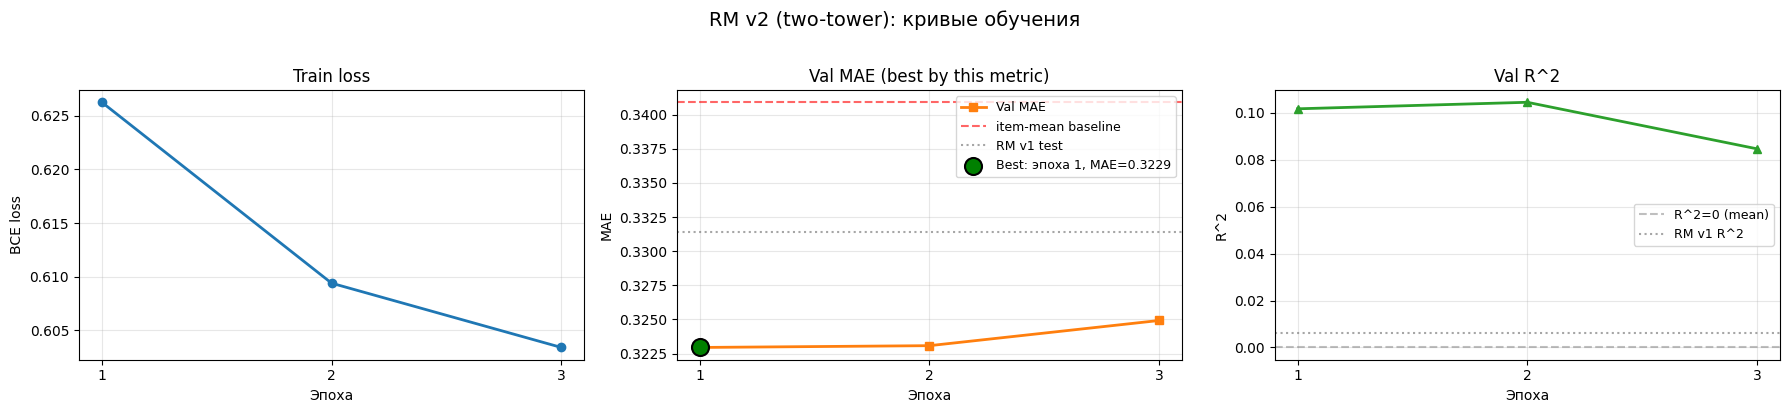


Сохранено: ..\results\rm_training_curves_v2.png

Итоговые метрики:
  Best epoch (by val MAE): 1
  Val MAE = 0.3229, Val R^2 = 0.1017
  Test MAE = 0.3308, Test R^2 = 0.0609


In [15]:
epochs = list(range(1, len(history['train_loss']) + 1))

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# --- 1. Train loss ---
axes[0].plot(epochs, history['train_loss'], marker='o', color='C0', linewidth=2)
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('BCE loss')
axes[0].set_title('Train loss')
axes[0].grid(alpha=0.3)
axes[0].set_xticks(epochs)

# --- 2. Val MAE (главная метрика) ---
axes[1].plot(epochs, history['val_mae'], marker='s', color='C1', linewidth=2, label='Val MAE')
axes[1].axhline(y=0.3409, color='red', linestyle='--', alpha=0.6, label='item-mean baseline')
axes[1].axhline(y=0.3314, color='gray', linestyle=':', alpha=0.7, label='RM v1 test')

# Отмечаем лучшую эпоху
best_epoch_idx = int(np.argmin(history['val_mae']))
best_epoch = epochs[best_epoch_idx]
best_mae = history['val_mae'][best_epoch_idx]
axes[1].scatter([best_epoch], [best_mae], s=150, color='green',
                zorder=5, edgecolors='black', linewidths=1.5,
                label=f'Best: эпоха {best_epoch}, MAE={best_mae:.4f}')

axes[1].set_xlabel('Эпоха')
axes[1].set_ylabel('MAE')
axes[1].set_title('Val MAE (best by this metric)')
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)
axes[1].set_xticks(epochs)

# --- 3. Val R^2 ---
axes[2].plot(epochs, history['val_r2'], marker='^', color='C2', linewidth=2)
axes[2].axhline(y=0.0, color='gray', linestyle='--', alpha=0.5, label='R^2=0 (mean)')
axes[2].axhline(y=0.0061, color='gray', linestyle=':', alpha=0.7, label='RM v1 R^2')
axes[2].set_xlabel('Эпоха')
axes[2].set_ylabel('R^2')
axes[2].set_title('Val R^2')
axes[2].legend(fontsize=9)
axes[2].grid(alpha=0.3)
axes[2].set_xticks(epochs)

fig.suptitle('RM v2 (two-tower): кривые обучения', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(RESULTS / 'rm_training_curves_v2.png', dpi=120, bbox_inches='tight')
plt.show()

print(f"\nСохранено: {RESULTS / 'rm_training_curves_v2.png'}")
print(f"\nИтоговые метрики:")
print(f"  Best epoch (by val MAE): {best_epoch}")
print(f"  Val MAE = {best_mae:.4f}, Val R^2 = {history['val_r2'][best_epoch_idx]:.4f}")
print(f"  Test MAE = {test_metrics['mae']:.4f}, Test R^2 = {test_metrics['r2']:.4f}")